In [1]:
import pandas as pd
from neo4j import GraphDatabase, RoutingControl
from tqdm import tqdm
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
from sklearn.neighbors import NearestNeighbors

# 1.2 Mempelajari Penggunaan Driver Neo4J

In [2]:
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "akumau50")

In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

In [4]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Cecep", "Mamat")
    add_friend(driver, "Cecep", "Asep")
    add_friend(driver, "Cecep", "Rudi")
    print_friends(driver, "Cecep")

Asep
Mamat
Rudi


## CHECKPOINT

1. Apa nama database yang digunakan pada tutorial ini?
2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database
lain dalam 1 instance!
3. Apa jenis graf pertemanan yang telah dibuat di sini?

### Jawaban
1. neo4j
2. DDL CYPHER, DML CYPHER, :use
3. directed graph

# 1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J

In [14]:
driver = GraphDatabase.driver(uri="neo4j://127.0.0.1:7687", auth=("neo4j", "akumau50"))
session = driver.session(database="system")

In [10]:
import os
import sys

csv_file_path = os.path.join("events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

In [11]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    
    CALL {
         WITH v, i, row
         WITH v, i, row WHERE row.event = 'view'
         CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

         UNION ALL

         WITH v, i, row
         WITH v, i, row WHERE row.event = 'addtocart'
         CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

         UNION ALL

         WITH v, i, row
         WITH v, i, row WHERE row.event = 'transaction'
         CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [12]:
import pandas as pd
from tqdm import tqdm
import math

batch_size = 5000
total_rows = 500000  # ambil sebagian 


def create_constraints(session):
    session.run(
        "CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS "
        "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"
    ).consume()

    session.run(
        "CREATE CONSTRAINT item_id_unique IF NOT EXISTS "
        "FOR (i:Item) REQUIRE i.itemId IS UNIQUE"
    ).consume()

    session.run(
        "CREATE CONSTRAINT transaction_id_unique IF NOT EXISTS "
        "FOR (t:Transaction) REQUIRE t.transactionId IS UNIQUE"
    ).consume()

    # Only useful if you import category_tree.csv; delete this block otherwise
    session.run(
        "CREATE CONSTRAINT category_id_unique IF NOT EXISTS "
        "FOR (c:Category) REQUIRE c.categoryId IS UNIQUE"
    ).consume()


def run_import(driver, csv_file_path):
    with driver.session(database="neo4j") as session:
        create_constraints(session)          # must run BEFORE the import

        print(f"Membaca file data dari: {csv_file_path}")
        chunks = pd.read_csv(
            csv_file_path,
            chunksize=batch_size,
            nrows=total_rows,                 # actually stops at 2M rows
            dtype={"transactionid": "string"},  # avoid "123.0"
        )
        total_chunks = math.ceil(total_rows / batch_size)

        print("Memulai proses impor data ke Neo4j...")
        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
            # Membersihkan data null/NaN pada transactionid
            chunk["transactionid"] = chunk["transactionid"].fillna("")
            records = chunk.to_dict(orient="records")
            session.execute_write(import_batch, records)


try:
    run_import(driver, csv_file_path)
    print("Proses impor berhasil.")
finally:
    driver.close()

Membaca file data dari: events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data:   0%|          | 0/100 [00:00<?, ?it/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=8, column=5, offset=140>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 140, 'line': 8, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n\n    CALL {\n         WITH v, i, row\n         WITH v, i, row WHERE row.event = 'view'\n         CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n         UNION ALL\n\n         WITH v, 

Proses impor berhasil.


In [15]:
FORCE_RESET = False

records, _, _ = driver.execute_query("MATCH (n) RETURN count(n) AS total_nodes", database_="neo4j")
current_nodes = records[0]["total_nodes"]

if current_nodes > 10 and not FORCE_RESET:
    print(f"Database contains full dataset ({current_nodes:,} nodes). Reset skipped to protect data.")
else:
    print("Resetting database...")
    while True:
        records, _, _ = driver.execute_query(
            "MATCH (n) WITH n LIMIT 10000 DETACH DELETE n RETURN count(n) AS deleted;",
            database_="neo4j"
        )
        if records[0]["deleted"] == 0:
            break
    print("Database reset complete.")

Database contains full dataset (364,007 nodes). Reset skipped to protect data.


# SOAL UTS

## 2.1 Wrangling dan EDA

### 1. 1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yg dipilih per individu tidak boleh sama dalam 1 kelas.  Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 - 06/2024.

Di nomor 1 ini, saya menggunakan periode waktu :

P1 Start = 29 Mei 2015 (timestamp = 1432857600738 ms)

P1 End   = 7 Juni 2015 (timestamp = 1433635216394 ms)

P2 Start = 8 Juni 2015 (timestamp = 1433721603362 ms)

P2 End   = 17 Juni 2015 (timestamp = 1434499200695 ms)

### 2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [16]:
from pathlib import Path

# Lokasi file CSV
csv_file_path = Path("events.csv")
output_file_path = Path("events_filtered.csv")

# Membaca data
df = pd.read_csv(csv_file_path)

# Mengubah timestamp Unix milidetik menjadi tanggal UTC
df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    utc=True,
    errors="coerce"
)

# Periode P1: 29 Mei sampai 7 Juni 2015
p1_start = pd.Timestamp("2015-05-29", tz="UTC")
p1_end = pd.Timestamp("2015-06-08", tz="UTC")

# Periode P2: 8 Juni sampai 17 Juni 2015
p2_start = pd.Timestamp("2015-06-08", tz="UTC")
p2_end = pd.Timestamp("2015-06-17", tz="UTC")

# Filter data berdasarkan timestamp
p1 = df[
    (df["datetime"] >= p1_start) &
    (df["datetime"] < p1_end)
].copy()

p2 = df[
    (df["datetime"] >= p2_start) &
    (df["datetime"] < p2_end)
].copy()

# Menambahkan label periode
p1["period"] = "P1"
p2["period"] = "P2"

# Menggabungkan data P1 dan P2
filtered_df = pd.concat([p1, p2], ignore_index=True)

# Menghapus kolom datetime tambahan jika tidak diperlukan
filtered_df.drop(columns=["datetime"], inplace=True)

# Menyimpan hasil ke CSV
filtered_df.to_csv(output_file_path, index=False)

# Menampilkan ringkasan
print("Proses filter selesai!")
print(f"Jumlah data P1: {len(p1):,}")
print(f"Jumlah data P2: {len(p2):,}")
print(f"Total data: {len(filtered_df):,}")
print(f"File hasil: {output_file_path.resolve()}")

Proses filter selesai!
Jumlah data P1: 198,446
Jumlah data P2: 178,785
Total data: 377,231
File hasil: C:\Users\Faiz\Documents\SEM_5\GSD\events_filtered.csv


### 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [ ]:
# Konfigurasi koneksi Neo4j
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "akumau50")
DATABASE = "neo4j"

def get_subgraph_composition(driver):
    with driver.session(database=DATABASE) as session:

        # Menghitung jumlah node berdasarkan label
        node_query = """
        MATCH (n)
        UNWIND labels(n) AS label
        RETURN label, count(*) AS jumlah
        ORDER BY label
        """

        node_result = session.run(node_query)
        node_data = [record.data() for record in node_result]

        # Menghitung jumlah relationship berdasarkan tipe
        relationship_query = """
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relationship,
               count(r) AS jumlah
        ORDER BY jenis_relationship
        """

        relationship_result = session.run(relationship_query)
        relationship_data = [
            record.data() for record in relationship_result
        ]

        return node_data, relationship_data


with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()

    nodes, relationships = get_subgraph_composition(driver)

    print("KOMPOSISI NODE")
    print(pd.DataFrame(nodes).to_string(index=False))

    print("\nKOMPOSISI RELATIONSHIP")
    print(pd.DataFrame(relationships).to_string(index=False))


KOMPOSISI NODE
  label  jumlah
   Item  105420
 Person       4
Visitor  258583

KOMPOSISI RELATIONSHIP
jenis_relationship  jumlah
     ADDED_TO_CART   50505
            BOUGHT   16876
             KNOWS       3
        SIMILAR_TO       5
            VIEWED 1948619


#### Komposisi Subgraph Menggunakan Python API Neo4j
Query dilakukan untuk mengetahui komposisi subgraph yang tersimpan dalam database Neo4j. Analisis ini bertujuan untuk mengidentifikasi jenis simpul (node) beserta jumlahnya, serta jenis relasi (relationship) beserta jumlahnya. Proses pengambilan data dilakukan menggunakan Python API Neo4j dengan menjalankan perintah Cypher.

Berdasarkan hasil eksekusi query, diperoleh komposisi simpul sebagai berikut.
Jenis simpul (Label)	   
- Item	                    =  105.420
- Person	                =  4
- Visitor	                = 258.583
- Total kemunculan label	= 364.007

Terdapat tiga label simpul, yaitu Item, Person, dan Visitor. Label Visitor memiliki jumlah terbanyak, yaitu 258.583 simpul, yang merepresentasikan pengguna atau pengunjung dalam jaringan. Selanjutnya, terdapat 105.420 simpul Item yang merepresentasikan produk atau barang yang berinteraksi dengan pengunjung. Sementara itu, label Person hanya berjumlah 4 simpul.

Jenis relasi	  
- ADDED_TO_CART	    = 50.505
- BOUGHT	        = 16.876
- KNOWS	            = 3
- SIMILAR_TO	    = 5
- VIEWED	        = 1.948.619
- Total relasi	    = 2.016.008

Relasi VIEWED merupakan relasi yang paling dominan, dengan jumlah 1.948.619 relasi. Hal ini menunjukkan bahwa aktivitas melihat item merupakan interaksi yang paling banyak tercatat dalam subgraph. Relasi ADDED_TO_CART sebanyak 50.505 menunjukkan aktivitas memasukkan item ke keranjang, sedangkan BOUGHT sebanyak 16.876 menunjukkan aktivitas pembelian.

#### Penjelasan Cypher yang digunakan
1. Query untuk menghitung simpul berdasarkan label

MATCH (n)
UNWIND labels(n) AS label
RETURN label, count(*) AS jumlah
ORDER BY label

Penjelasan:
- MATCH (n) mengambil seluruh simpul yang terdapat dalam database Neo4j.
- labels(n) mengambil label yang dimiliki setiap simpul.
- UNWIND labels(n) AS label mengubah daftar label menjadi baris terpisah, sehingga simpul dapat dikelompokkan berdasarkan labelnya.
- RETURN label, count(*) AS jumlah menampilkan nama label dan jumlah kemunculannya.
- ORDER BY label mengurutkan hasil berdasarkan nama label secara alfabetis.

2. Query untuk menghitung relasi berdasarkan tipe

MATCH ()-[r]->()
RETURN type(r) AS jenis_relationship,
       count(r) AS jumlah
ORDER BY jenis_relationship

Penjelasan:
- MATCH ()-[r]->() mengambil seluruh relasi berarah dalam database tanpa membatasi label simpul asal maupun tujuan.
- type(r) mengambil tipe relasi, seperti VIEWED, ADDED_TO_CART, BOUGHT, KNOWS, dan SIMILAR_TO.
- count(r) AS jumlah menghitung banyaknya relasi untuk setiap tipe.
- ORDER BY jenis_relationship mengurutkan hasil berdasarkan tipe relasi secara alfabetis.

### 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

Berhasil terhubung ke Neo4j!

Properti pada node Item:
['itemId']
Properti ID Item: itemId

Data interaksi berhasil diambil.
Ukuran dataset: (400294, 4)
   user_id item_id   event  frequency
0  1239088       6  VIEWED          5
1  1282672       6  VIEWED          4
2   802121       6  VIEWED          8
3  1371759       6  VIEWED          4
4   667886       6  VIEWED          4

Jumlah interaksi per event:
event
ADDED_TO_CART      50505
BOUGHT             16876
VIEWED           1948619
Name: frequency, dtype: int32

VSM berhasil dibentuk!
Jumlah user: 258583
Jumlah item: 105420
Ukuran matriks: (258583, 105420)
Jumlah pasangan user-item: 387012
Sparsity matriks: 99.9986%
Memori data matriks: 1.48 MB

Contoh matriks VSM (5 user x 5 item):
           6   15   16   25   26
1239088  5.0  0.0  0.0  0.0  0.0
1282672  4.0  0.0  0.0  0.0  0.0
802121   8.0  0.0  0.0  0.0  0.0
1371759  4.0  0.0  0.0  0.0  0.0
667886   4.0  0.0  0.0  0.0  0.0


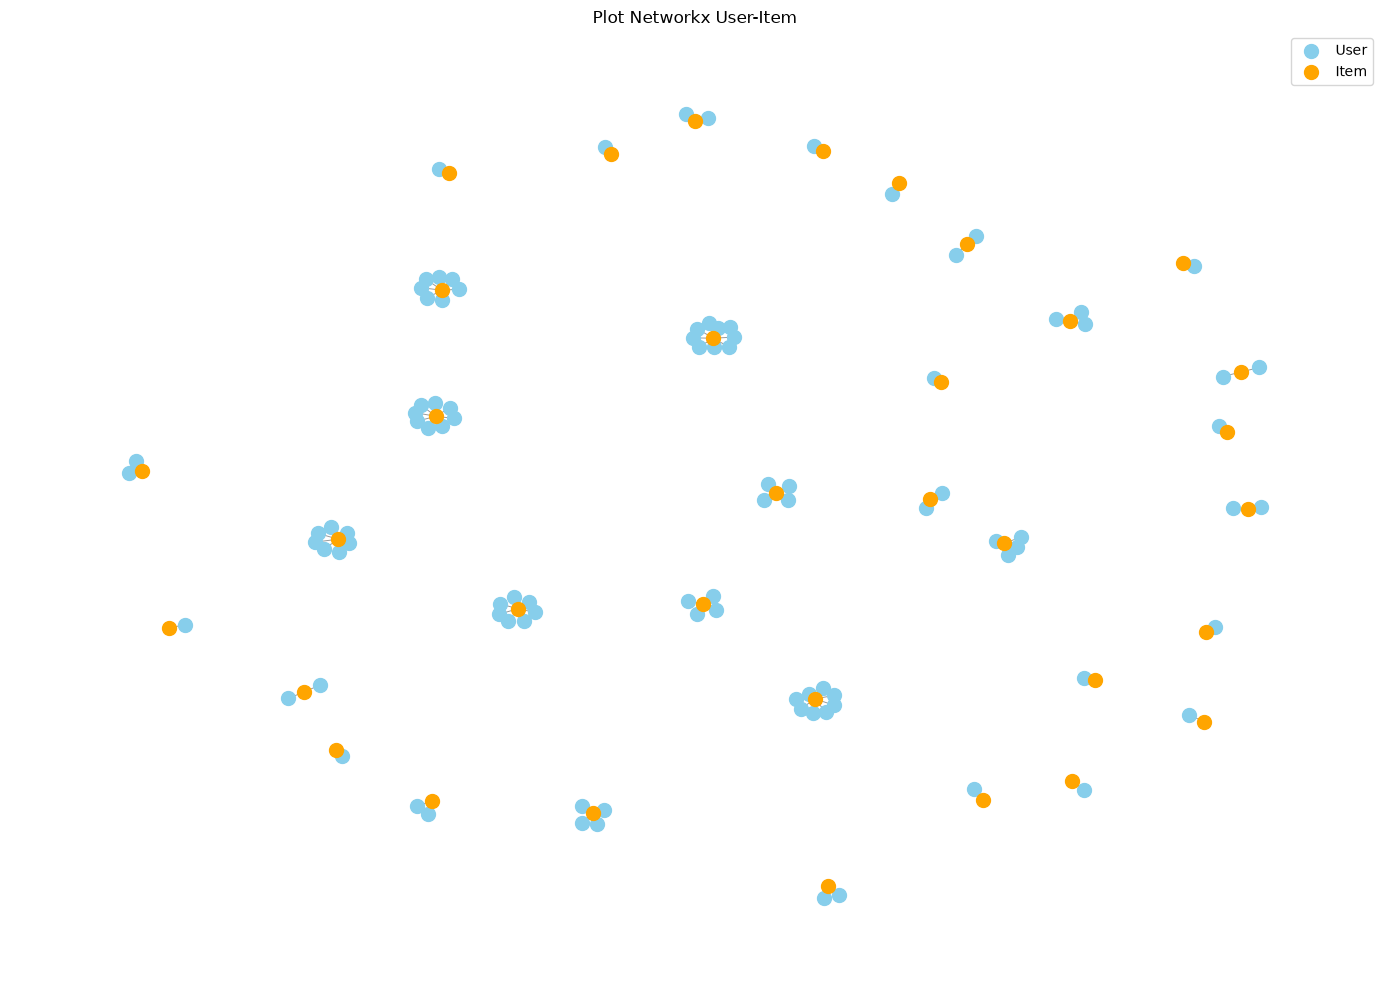


Jumlah node pada graf: 131
Jumlah edge pada graf: 97

Koneksi Neo4j ditutup.


In [ ]:
from scipy.sparse import coo_matrix, save_npz

# 2. KONEKSI NEO4J
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "akumau50")
DATABASE = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)

try:
    driver.verify_connectivity()
    print("Berhasil terhubung ke Neo4j!")


    # 3. DETEKSI PROPERTI ID ITEM
    with driver.session(database=DATABASE) as session:
        result = session.run("""
            MATCH (i:Item)
            RETURN keys(i) AS properties
            LIMIT 100
        """)

        property_rows = [
            record["properties"] for record in result
        ]

    item_properties = sorted({
        prop
        for properties in property_rows
        for prop in properties
    })

    print("\nProperti pada node Item:")
    print(item_properties)

    candidates = [
        "itemId", "itemid", "item_id",
        "id", "idItem", "itemID"
    ]

    item_property = next(
        (
            prop for prop in candidates
            if prop in item_properties
        ),
        None
    )

    if item_property is None:
        raise ValueError(
            "Properti ID Item tidak ditemukan. "
            "Periksa daftar properti Item di atas."
        )

    print("Properti ID Item:", item_property)


    # 4. AMBIL DATA INTERAKSI DARI NEO4J
    query = f"""
    MATCH (u:Visitor)-[r]->(i:Item)
    WHERE u.visitorId IS NOT NULL
      AND i.`{item_property}` IS NOT NULL
      AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
    RETURN
        toString(u.visitorId) AS user_id,
        toString(i.`{item_property}`) AS item_id,
        type(r) AS event,
        count(r) AS frequency
    """

    with driver.session(database=DATABASE) as session:
        result = session.run(query)
        records = [record.data() for record in result]

    df = pd.DataFrame(records)

    if df.empty:
        raise ValueError(
            "Data interaksi kosong. Periksa label, "
            "relationship, dan nama properti ID."
        )

    df["user_id"] = df["user_id"].astype(str)
    df["item_id"] = df["item_id"].astype(str)
    df["frequency"] = df["frequency"].astype("int32")

    print("\nData interaksi berhasil diambil.")
    print("Ukuran dataset:", df.shape)
    print(df.head())

    print("\nJumlah interaksi per event:")
    print(df.groupby("event")["frequency"].sum())


    # 5. MEMBENTUK VSM DENGAN SPARSE MATRIX
    users = pd.Index(df["user_id"].unique())
    items = pd.Index(df["item_id"].unique())

    user_codes = users.get_indexer(df["user_id"])
    item_codes = items.get_indexer(df["item_id"])

    X = coo_matrix(
        (
            df["frequency"].to_numpy(dtype=np.float32),
            (user_codes, item_codes)
        ),
        shape=(len(users), len(items)),
        dtype=np.float32
    ).tocsr()

    # Jumlahkan interaksi dari berbagai event
    # untuk pasangan user-item yang sama
    X.sum_duplicates()

    print("\nVSM berhasil dibentuk!")
    print("Jumlah user:", len(users))
    print("Jumlah item:", len(items))
    print("Ukuran matriks:", X.shape)
    print("Jumlah pasangan user-item:", X.nnz)

    total_cells = X.shape[0] * X.shape[1]

    sparsity = (
        (1 - X.nnz / total_cells) * 100
        if total_cells > 0 else 0
    )

    print(f"Sparsity matriks: {sparsity:.4f}%")
    print(
        "Memori data matriks: "
        f"{X.data.nbytes / (1024**2):.2f} MB"
    )


    # 6. MENAMPILKAN CONTOH MATRIKS VSM
    sample_matrix = X[:5, :5].toarray()

    sample_df = pd.DataFrame(
        sample_matrix,
        index=users[:5],
        columns=items[:5]
    )

    print("\nContoh matriks VSM (5 user x 5 item):")
    print(sample_df)


    # 7. VISUALISASI JARINGAN USER-ITEM
    G = nx.Graph()

    # Batasi jumlah data untuk menjaga visualisasi ringan
    sample_edges = df.head(100)

    for _, row in sample_edges.iterrows():
        user_node = "User_" + str(row["user_id"])
        item_node = "Item_" + str(row["item_id"])

        G.add_node(user_node, node_type="User")
        G.add_node(item_node, node_type="Item")

        if G.has_edge(user_node, item_node):
            G[user_node][item_node]["weight"] += int(
                row["frequency"]
            )
        else:
            G.add_edge(
                user_node,
                item_node,
                weight=int(row["frequency"]),
                event=row["event"]
            )

    plt.figure(figsize=(14, 10))

    pos = nx.spring_layout(G, seed=42)

    user_nodes = [
        node for node, data in G.nodes(data=True)
        if data["node_type"] == "User"
    ]

    item_nodes = [
        node for node, data in G.nodes(data=True)
        if data["node_type"] == "Item"
    ]

    nx.draw_networkx_nodes(
        G, pos,
        nodelist=user_nodes,
        node_color="skyblue",
        node_size=100,
        label="User"
    )

    nx.draw_networkx_nodes(
        G, pos,
        nodelist=item_nodes,
        node_color="orange",
        node_size=100,
        label="Item"
    )

    nx.draw_networkx_edges(
        G, pos,
        alpha=0.4,
        width=0.7
    )

    plt.title("Plot Networkx User-Item")
    plt.legend()
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    print("\nJumlah node pada graf:", G.number_of_nodes())
    print("Jumlah edge pada graf:", G.number_of_edges())


finally:
    driver.close()
    print("\nKoneksi Neo4j ditutup.")


In [20]:
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "akumau50")
DATABASE = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)

try:
    with driver.session(database=DATABASE) as session:

        # Cek label node
        result = session.run("""
            MATCH (n)
            UNWIND labels(n) AS label
            RETURN label, count(*) AS jumlah
            ORDER BY jumlah DESC
        """)
        print("=== LABEL NODE ===")
        print(pd.DataFrame([r.data() for r in result]))

        # Cek relationship
        result = session.run("""
            MATCH (a)-[r]->(b)
            RETURN labels(a) AS node_awal,
                   type(r) AS relationship,
                   labels(b) AS node_akhir,
                   count(*) AS jumlah
            ORDER BY jumlah DESC
        """)
        print("\n=== RELATIONSHIP ===")
        print(pd.DataFrame([r.data() for r in result]))

        # Cek beberapa node beserta propertinya
        result = session.run("""
            MATCH (n)
            RETURN labels(n) AS label, properties(n) AS properti
            LIMIT 5
        """)
        print("\n=== CONTOH NODE ===")
        print(pd.DataFrame([r.data() for r in result]))

finally:
    driver.close()


=== LABEL NODE ===
     label  jumlah
0  Visitor  258583
1     Item  105420
2   Person       4

=== RELATIONSHIP ===
   node_awal   relationship node_akhir   jumlah
0  [Visitor]         VIEWED     [Item]  1948619
1  [Visitor]  ADDED_TO_CART     [Item]    50505
2  [Visitor]         BOUGHT     [Item]    16876
3     [Item]     SIMILAR_TO     [Item]        5
4   [Person]          KNOWS   [Person]        3

=== CONTOH NODE ===
       label               properti
0   [Person]      {'name': 'Cecep'}
1   [Person]      {'name': 'Mamat'}
2   [Person]       {'name': 'Asep'}
3   [Person]       {'name': 'Rudi'}
4  [Visitor]  {'visitorId': 257597}


#### Karakteristik Vector Space Modelling (VSM) yang dihasilkan adalah sebagai berikut.

1. Jenis dan jumlah simpul (node)
Database Neo4j memiliki tiga label simpul, yaitu Visitor sebanyak 258.583 simpul, Item sebanyak 105.420 simpul, dan Person sebanyak 4 simpul. Namun, dalam pembentukan VSM, simpul yang digunakan hanya Visitor dan Item, sehingga matriks merepresentasikan interaksi pengguna dengan produk.

2. Jenis dan jumlah relasi (relationship)

Berdasarkan hasil pemeriksaan database, terdapat empat jenis relasi:
- VIEWED: 1.465.335 relasi.
- ADDED_TO_CART: 37.974 relasi.
- BOUGHT: 12.691 relasi.
- KNOWS: 3 relasi.
Relasi VIEWED, ADDED_TO_CART, dan BOUGHT menghubungkan simpul Visitor dengan Item, sedangkan KNOWS menghubungkan simpul Person dengan Person. Oleh karena itu, hanya tiga relasi pertama yang digunakan untuk membentuk VSM.

3. Dimensi matriks VSM
Matriks VSM memiliki dimensi 258.583 × 105.420, dengan baris mewakili pengguna dan kolom mewakili item. Setiap pengguna direpresentasikan sebagai vektor berdimensi 105.420 yang berisi frekuensi interaksi terhadap setiap item.

4. Visualisasi jaringan NetworkX
Graf yang divisualisasikan menggunakan sampel 100 baris pertama data interaksi menghasilkan 131 simpul dan 97 edge. Simpul berwarna biru merepresentasikan pengguna, sedangkan simpul oranye merepresentasikan item. Edge menunjukkan adanya interaksi antara pengguna dan produk. Karena visualisasi menggunakan sampel data, jumlah simpul dan edge pada gambar tidak mewakili keseluruhan jaringan Neo4j.


### 5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [21]:
from scipy.sparse import coo_matrix

# df berasal dari hasil query Neo4j sebelumnya:
# user_id, item_id, event, frequency

# Pastikan ID berbentuk string
df["user_id"] = df["user_id"].astype(str)
df["item_id"] = df["item_id"].astype(str)

# Indeks unik Item dan Visitor
items = pd.Index(df["item_id"].unique())
visitors = pd.Index(df["user_id"].unique())

# Konversi ID menjadi indeks numerik
item_codes = items.get_indexer(df["item_id"])
visitor_codes = visitors.get_indexer(df["user_id"])

# Bentuk matriks Item-Visitor
X_item = coo_matrix(
    (
        df["frequency"].to_numpy(dtype=np.float32),
        (item_codes, visitor_codes)
    ),
    shape=(len(items), len(visitors)),
    dtype=np.float32
).tocsr()

# Gabungkan interaksi dari event yang berbeda
X_item.sum_duplicates()

# Informasi matriks
print("Jumlah Item:", len(items))
print("Jumlah Visitor:", len(visitors))
print("Dimensi matriks:", X_item.ndim)
print("Shape matriks:", X_item.shape)
print("Jumlah nilai nonzero:", X_item.nnz)

total_cells = X_item.shape[0] * X_item.shape[1]
sparsity = (
    (1 - X_item.nnz / total_cells) * 100
    if total_cells else 0
)

print(f"Sparsity: {sparsity:.4f}%")
print(
    f"Memori data nonzero: "
    f"{X_item.data.nbytes / (1024**2):.2f} MB"
)

Jumlah Item: 105420
Jumlah Visitor: 258583
Dimensi matriks: 2
Shape matriks: (105420, 258583)
Jumlah nilai nonzero: 387012
Sparsity: 99.9986%
Memori data nonzero: 1.48 MB


In [22]:
# Total interaksi setiap Item dan Visitor
item_totals = np.asarray(X_item.sum(axis=1)).ravel()
visitor_totals = np.asarray(X_item.sum(axis=0)).ravel()

# Ambil 20 dengan interaksi tertinggi
top_item_idx = np.argsort(item_totals)[-20:][::-1]
top_visitor_idx = np.argsort(visitor_totals)[-20:][::-1]

# Konversi subset kecil menjadi matriks padat
small_matrix = X_item[top_item_idx, :][:, top_visitor_idx].toarray()

vsm_df = pd.DataFrame(
    small_matrix,
    index=[items[i] for i in top_item_idx],
    columns=[visitors[i] for i in top_visitor_idx]
)

print("Shape subset VSM:", vsm_df.shape)
display(vsm_df)

Shape subset VSM: (20, 20)


,684514,765630,1150086,1161163,76757,836635,371604,138131,286616,1093035,85734,548772,163561,892355,468309,748040,95405,343137,77390,213145
5411,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
309778,0.0,0.0,4.0,0.0,0.0,4.0,0.0,28.0,4.0,8.0,4.0,0.0,0.0,8.0,0.0,0.0,0.0,8.0,0.0,0.0
257040,4.0,4.0,0.0,12.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0
194791,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
298009,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
370653,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7943,12.0,4.0,4.0,8.0,12.0,0.0,12.0,5.0,18.0,0.0,0.0,0.0,8.0,4.0,0.0,0.0,0.0,0.0,4.0,0.0
461686,12.0,4.0,20.0,16.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0
111530,8.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
335975,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


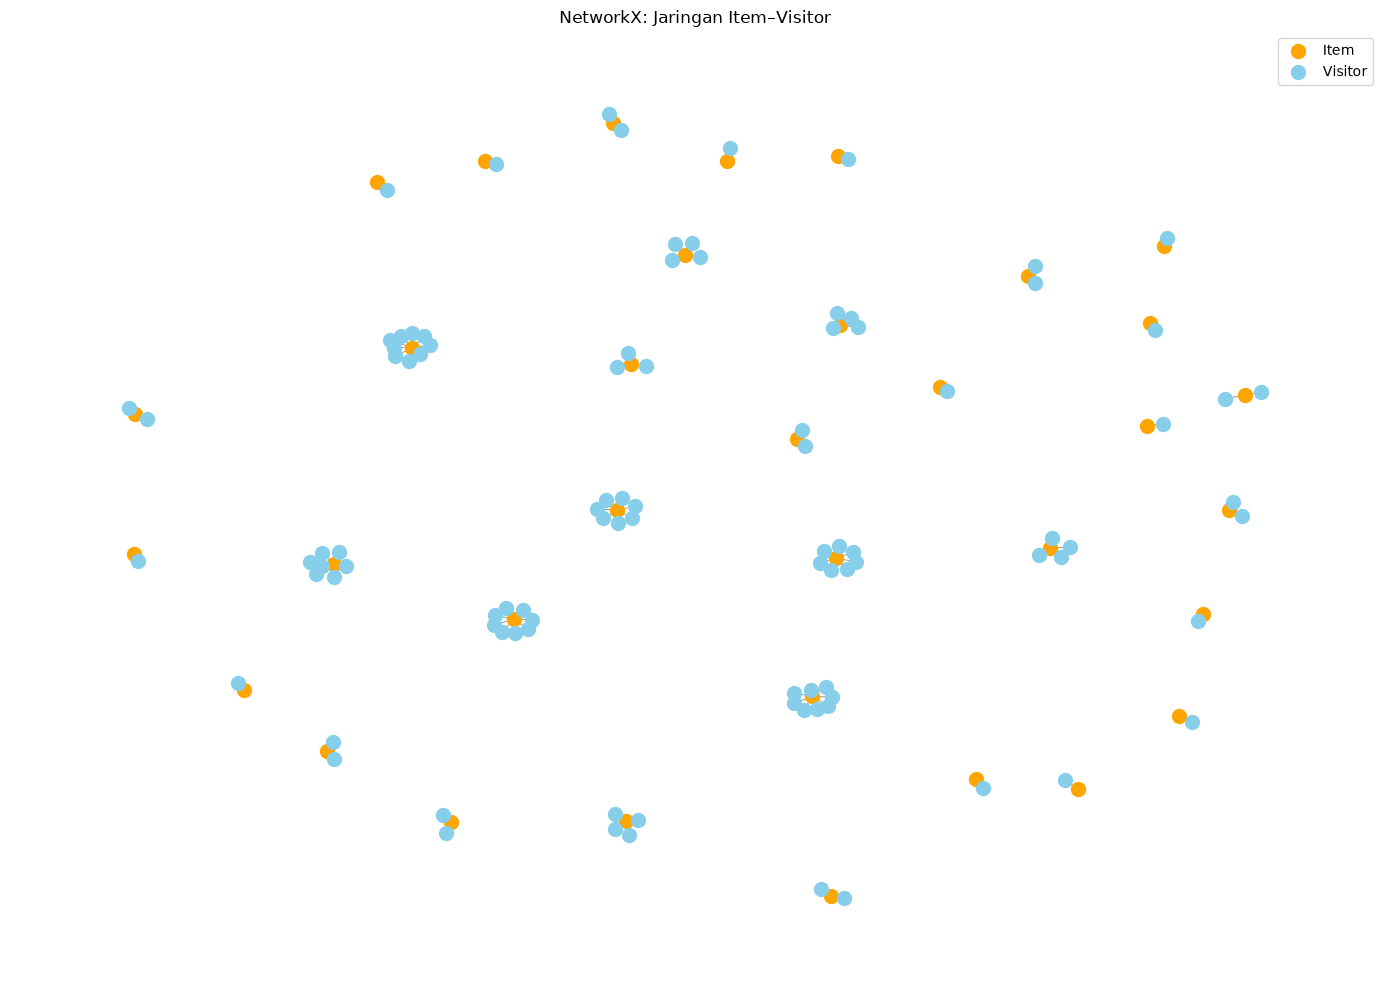

Jumlah simpul pada graf: 131
Jumlah edge pada graf: 97
Jumlah simpul Item: 34
Jumlah simpul Visitor: 97


In [23]:
G = nx.Graph()

sample_edges = df.head(100)

for _, row in sample_edges.iterrows():
    item_node = "Item_" + str(row["item_id"])
    visitor_node = "Visitor_" + str(row["user_id"])

    G.add_node(item_node, node_type="Item")
    G.add_node(visitor_node, node_type="Visitor")

    if G.has_edge(item_node, visitor_node):
        G[item_node][visitor_node]["weight"] += int(
            row["frequency"]
        )
    else:
        G.add_edge(
            item_node,
            visitor_node,
            weight=int(row["frequency"])
        )

# Visualisasi graf
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, seed=42)

item_nodes = [
    n for n, d in G.nodes(data=True)
    if d["node_type"] == "Item"
]

visitor_nodes = [
    n for n, d in G.nodes(data=True)
    if d["node_type"] == "Visitor"
]

nx.draw_networkx_nodes(
    G, pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=100,
    label="Item"
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=visitor_nodes,
    node_color="skyblue",
    node_size=100,
    label="Visitor"
)

nx.draw_networkx_edges(
    G, pos,
    alpha=0.4,
    width=0.7
)

plt.title("NetworkX: Jaringan Item–Visitor")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah simpul pada graf:", G.number_of_nodes())
print("Jumlah edge pada graf:", G.number_of_edges())
print("Jumlah simpul Item:", len(item_nodes))
print("Jumlah simpul Visitor:", len(visitor_nodes))

#### Karakteristik Vector Space Modelling (VSM) pada Simpul Item
Berdasarkan hasil pengolahan data, karakteristik VSM dengan simpul yang diasumsikan sebagai Item adalah sebagai berikut.

1. Jumlah simpul: Terdapat 105.420 simpul Item dan 258.583 simpul Visitor dalam database. Pada VSM ini, Item menjadi representasi baris, sedangkan Visitor menjadi representasi kolom.

2. Dimensi dan shape matriks: Matriks VSM memiliki 2 dimensi dengan shape (105.420, 258.583). Artinya, terdapat 105.420 baris yang mewakili item dan 258.583 kolom yang mewakili visitor. Setiap item direpresentasikan sebagai vektor berdimensi 258.583 berdasarkan frekuensi interaksi dengan setiap visitor.

3. Visualisasi jaringan NetworkX: Graf yang dihasilkan terdiri atas 131 simpul dan 97 edge, dengan rincian 34 simpul Item dan 97 simpul Visitor. Simpul Item ditampilkan dengan warna oranye, sedangkan simpul Visitor ditampilkan dengan warna biru. Garis yang menghubungkan keduanya menunjukkan hubungan interaksi. Visualisasi ini menggunakan sampel data sehingga tidak menggambarkan keseluruhan jaringan.

VSM dengan Item sebagai simpul utama menghasilkan matriks berukuran 105.420 × 258.583. Matriks memiliki sparsity sangat tinggi, yaitu 99,9986%, sehingga format sparse matrix sesuai untuk menghemat memori dan mendukung analisis kemiripan antaritem berdasarkan pola interaksi dengan visitor.

### 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Berdasarkan eksplorasi nomor 4 dan 5, proyeksi yang lebih baik dapat ditentukan dari hasil visualisasi dan efisiensi komputasi masing-masing proyeksi. Jika nomor 4 dan 5 membandingkan representasi VSM dengan proyeksi jaringan menggunakan NetworkX, uraian yang dapat digunakan adalah sebagai berikut.

Proyeksi yang lebih efektif dan efisien adalah proyeksi VSM dalam bentuk Sparse Matrix untuk pengolahan data berskala besar. Sparse Matrix hanya menyimpan nilai yang tidak nol sehingga penggunaan memori lebih hemat, terutama ketika sebagian besar pasangan simpul tidak memiliki interaksi.

Sementara itu, proyeksi jaringan menggunakan NetworkX lebih efektif untuk memahami struktur hubungan antar-simpul, seperti hubungan antara Item dan Visitor, serta mengidentifikasi simpul yang memiliki banyak koneksi. Namun, visualisasi jaringan dapat menjadi lambat dan sulit dibaca ketika jumlah simpul dan edge sangat besar.

Dengan demikian, pemilihan proyeksi bergantung pada tujuan analisis. Sparse Matrix lebih sesuai untuk efisiensi penyimpanan dan perhitungan matematis, sedangkan NetworkX lebih sesuai untuk eksplorasi visual hubungan antar-simpul. Untuk dataset besar, keduanya dapat digunakan secara bersamaan: Sparse Matrix untuk komputasi utama dan NetworkX untuk visualisasi subset jaringan.

### 7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python
### (a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!


In [24]:
# Pilih Item acuan berdasarkan jumlah interaksi tertinggi
item_totals = np.asarray(X_item.sum(axis=1)).ravel()
reference_idx = int(np.argmax(item_totals))
reference_item = str(items[reference_idx])

print("Item acuan:", reference_item)
print("Jumlah interaksi:", int(item_totals[reference_idx]))

# Hitung similarity antara Item acuan dengan semua Item
similarities = cosine_similarity(
    X_item[reference_idx:reference_idx + 1],
    X_item
).ravel()

# Urutkan similarity tertinggi, kecuali Item acuan itu sendiri
ranking = np.argsort(similarities)[::-1]
ranking = [
    idx for idx in ranking
    if idx != reference_idx and similarities[idx] > 0
][:5]

top5 = pd.DataFrame({
    "reference_item": reference_item,
    "similar_item": [str(items[i]) for i in ranking],
    "similarity": [float(similarities[i]) for i in ranking]
})

print("\n5 Item dengan similarity tertinggi:")
display(top5)

Item acuan: 5411
Jumlah interaksi: 4473

5 Item dengan similarity tertinggi:


,reference_item,similar_item,similarity
0,5411,33030,0.208811
1,5411,89143,0.174475
2,5411,33956,0.136648
3,5411,459936,0.118027
4,5411,256242,0.111014


### (b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

In [25]:
driver = GraphDatabase.driver(URI, auth=AUTH)

try:
    # item_property berasal dari kode pendeteksian properti Item
    write_query = f"""
    MATCH (a:Item)
    WHERE toString(a.`{item_property}`) = $reference_item

    UNWIND $recommendations AS rec

    MATCH (b:Item)
    WHERE toString(b.`{item_property}`) = rec.item_id
      AND a <> b

    MERGE (a)-[r:SIMILAR_TO]->(b)
    SET r.similarity = rec.similarity,
        r.method = 'Cosine Similarity'

    RETURN
        toString(a.`{item_property}`) AS reference_item,
        toString(b.`{item_property}`) AS similar_item,
        r.similarity AS similarity
    ORDER BY similarity DESC
    """

    recommendations = top5[
        ["similar_item", "similarity"]
    ].to_dict("records")

    with driver.session(database=DATABASE) as session:
        result = session.run(
            write_query,
            reference_item=reference_item,
            recommendations=recommendations
        )
        saved_results = [record.data() for record in result]

    print("Hasil relasi similarity yang tersimpan:")
    display(pd.DataFrame(saved_results))

finally:
    driver.close()

Hasil relasi similarity yang tersimpan:


""


In [ ]:
# 1. HITUNG COSINE SIMILARITY
item_totals = np.asarray(X_item.sum(axis=1)).ravel()

# Item acuan dengan jumlah interaksi terbanyak
reference_idx = int(np.argmax(item_totals))
reference_item = str(items[reference_idx])

similarities = cosine_similarity(
    X_item[reference_idx:reference_idx + 1],
    X_item
).ravel()

# Ambil 5 Item paling mirip, tanpa Item acuan
ranking = np.argsort(similarities)[::-1]
ranking = [
    i for i in ranking
    if i != reference_idx and similarities[i] > 0
][:5]

top5 = pd.DataFrame({
    "Item_Mirip": [str(items[i]) for i in ranking],
    "Similarity": [float(similarities[i]) for i in ranking]
})

top5["Item_Acuan"] = reference_item

print("Item acuan:", reference_item)
print("\nHasil perhitungan similarity:")
display(top5[["Item_Acuan", "Item_Mirip", "Similarity"]])


# 2. SIMPAN RELASI KE NEO4J
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "akumau50")
DATABASE = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)

try:
    # Buat relasi SIMILAR_TO dan simpan nilai similarity
    save_query = f"""
    MATCH (a:Item)
    WHERE toString(a.`{item_property}`) = $reference_item

    UNWIND $recommendations AS rec

    MATCH (b:Item)
    WHERE toString(b.`{item_property}`) = rec.item_id
      AND a <> b

    MERGE (a)-[r:SIMILAR_TO]->(b)
    SET r.similarity = rec.similarity,
        r.method = 'Cosine Similarity'

    RETURN
        toString(a.`{item_property}`) AS Item_Acuan,
        toString(b.`{item_property}`) AS Item_Mirip,
        r.similarity AS Similarity
    ORDER BY Similarity DESC
    """

    recommendations = [
        {
            "item_id": row["Item_Mirip"],
            "similarity": row["Similarity"]
        }
        for _, row in top5.iterrows()
    ]

    with driver.session(database=DATABASE) as session:
        saved = session.run(
            save_query,
            reference_item=reference_item,
            recommendations=recommendations
        ).data()

        print("\nRelasi yang berhasil disimpan:")
        display(pd.DataFrame(saved))

        # 3. QUERY NOMOR 7B
        result_query = f"""
        MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
        WHERE toString(a.`{item_property}`) = $reference_item

        RETURN
            toString(a.`{item_property}`) AS Item_Acuan,
            toString(b.`{item_property}`) AS Item_Mirip,
            round(r.similarity * 10000) / 10000.0 AS Similarity,
            r.method AS Metode

        ORDER BY r.similarity DESC
        LIMIT 5
        """

        results = session.run(
            result_query,
            reference_item=reference_item
        ).data()

        hasil_7b = pd.DataFrame(results)

        print("\nOUTPUT NOMOR 7B: TOP 5 SIMILARITY DARI NEO4J")

        if hasil_7b.empty:
            print(
                "Relasi tidak ditemukan. Periksa apakah properti ID "
                "Item sesuai dan Item acuan tersedia di Neo4j."
            )
        else:
            display(hasil_7b)

finally:
    driver.close()

Item acuan: 5411

Hasil perhitungan similarity:


,Item_Acuan,Item_Mirip,Similarity
0,5411,33030,0.208811
1,5411,89143,0.174475
2,5411,33956,0.136648
3,5411,459936,0.118027
4,5411,256242,0.111014



Relasi yang berhasil disimpan:


,Item_Acuan,Item_Mirip,Similarity
0,5411,33030,0.208811
1,5411,89143,0.174475
2,5411,33956,0.136648
3,5411,459936,0.118027
4,5411,256242,0.111014



OUTPUT NOMOR 7B: TOP 5 SIMILARITY DARI NEO4J


,Item_Acuan,Item_Mirip,Similarity,Metode
0,5411,33030,0.2088,Cosine Similarity
1,5411,89143,0.1745,Cosine Similarity
2,5411,33956,0.1366,Cosine Similarity
3,5411,459936,0.1180,Cosine Similarity
4,5411,256242,0.1110,Cosine Similarity


### 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

#### A. Sebelum perhitungan similarity


TABEL INTERAKSI SEBELUM SIMILARITY


,visitor_id,interaction,item_id
0,257597,VIEWED,355908
1,257597,VIEWED,355908
2,257597,VIEWED,355908
3,257597,VIEWED,355908
4,257597,VIEWED,355908
5,981382,VIEWED,355908
6,981382,VIEWED,355908
7,981382,VIEWED,355908
8,981382,VIEWED,355908
9,979686,VIEWED,355908


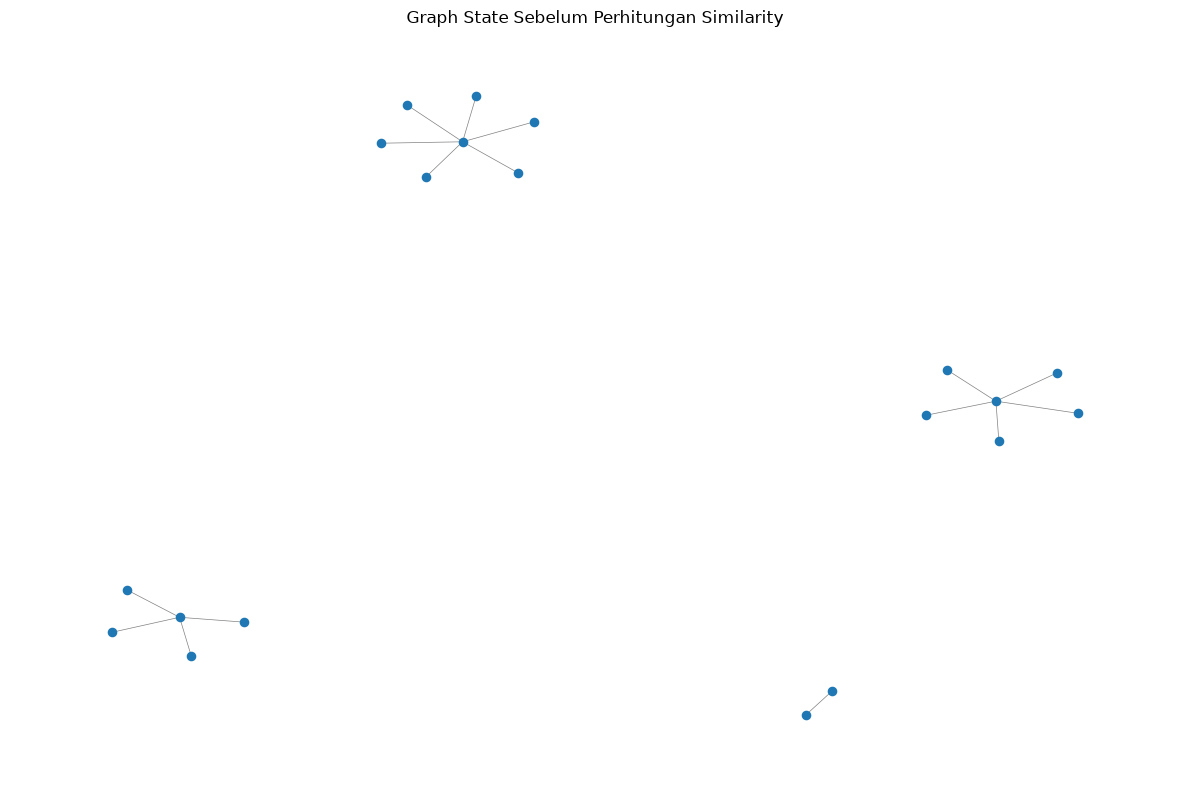

In [29]:
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "akumau50")
DATABASE = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)

query_before = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN
    toString(v.visitorId) AS visitor_id,
    type(r) AS interaction,
    toString(i.itemId) AS item_id
LIMIT 100
"""

with driver.session(database=DATABASE) as session:
    records_before = list(session.run(query_before))

df_before = pd.DataFrame(records_before, columns=[
    "visitor_id", "interaction", "item_id"
])

print("TABEL INTERAKSI SEBELUM SIMILARITY")
display(df_before.head(10))

G_before = nx.Graph()

for _, row in df_before.iterrows():
    visitor = "Visitor " + str(row["visitor_id"])
    item = "Item " + str(row["item_id"])

    G_before.add_node(visitor, node_type="Visitor")
    G_before.add_node(item, node_type="Item")
    G_before.add_edge(
        visitor, item,
        interaction=row["interaction"]
    )

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_before, seed=42)

nx.draw_networkx(
    G_before,
    pos,
    with_labels=False,
    node_size=35,
    edge_color="gray",
    width=0.5
)

plt.title("Graph State Sebelum Perhitungan Similarity")
plt.axis("off")
plt.tight_layout()
plt.show()

Sebelum perhitungan similarity, graf berisi relasi interaksi antara Visitor dan Item, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT. Relasi SIMILAR_TO belum ditambahkan oleh proses perhitungan similarity.

Gunakan query Cypher berikut untuk menampilkan graf interaksi awal:
```cypher
query_before = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN
    toString(v.visitorId) AS visitor_id,
    type(r) AS interaction,
    toString(i.itemId) AS item_id
LIMIT 100
"""
```
Query ini mengambil maksimal 100 relasi interaksi antara Visitor dan Item, meliputi aktivitas melihat barang, menambahkan barang ke keranjang, dan membeli barang. Hasilnya digunakan untuk membentuk graf awal yang menggambarkan pola interaksi pengguna dengan item.

#### B. Sesudah perhitungan similarity

In [30]:
query_after = """
MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
RETURN
    toString(a.itemId) AS Item_Acuan,
    toString(b.itemId) AS Item_Mirip,
    r.similarity AS Similarity,
    r.method AS Metode
ORDER BY r.similarity DESC
LIMIT 5
"""

with driver.session(database=DATABASE) as session:
    records_after = list(session.run(query_after))

df_after = pd.DataFrame(records_after, columns=[
    "Item_Acuan", "Item_Mirip", "Similarity", "Metode"
])

print("TABEL HASIL SIMILARITY")
display(df_after)

TABEL HASIL SIMILARITY


,Item_Acuan,Item_Mirip,Similarity,Metode
0,5411,33030,0.208811,Cosine Similarity
1,5411,89143,0.174475,Cosine Similarity
2,5411,33956,0.136648,Cosine Similarity
3,5411,459936,0.118027,Cosine Similarity
4,5411,256242,0.111014,Cosine Similarity


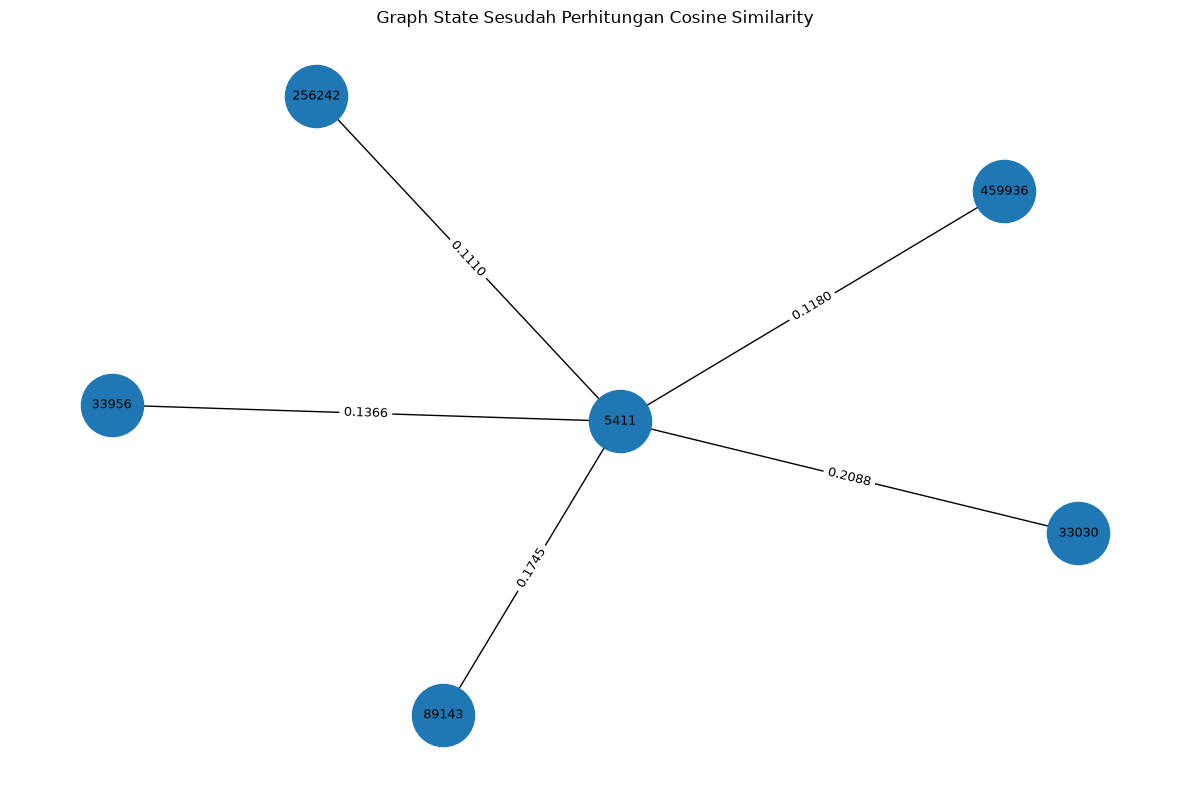

In [34]:
G_after = nx.DiGraph()

for _, row in df_after.iterrows():
    G_after.add_edge(
        str(row["Item_Acuan"]),
        str(row["Item_Mirip"]),
        weight=float(row["Similarity"])
    )

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_after, seed=42)

nx.draw_networkx_nodes(
    G_after, pos,
    node_size=2000
)

nx.draw_networkx_labels(
    G_after, pos,
    font_size=9
)

nx.draw_networkx_edges(
    G_after, pos,
    arrows=True,
    arrowsize=20
)

edge_labels = {
    (u, v): f"{data['weight']:.4f}"
    for u, v, data in G_after.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G_after, pos,
    edge_labels=edge_labels,
    font_size=9
)

plt.title("Graph State Sesudah Perhitungan Cosine Similarity")
plt.axis("off")
plt.tight_layout()
plt.show()

```
query_after = """
MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
RETURN
    toString(a.itemId) AS Item_Acuan,
    toString(b.itemId) AS Item_Mirip,
    r.similarity AS Similarity,
    r.method AS Metode
ORDER BY r.similarity DESC
LIMIT 5
"""
```

Query ini mengambil maksimal lima relasi SIMILAR_TO dengan nilai Cosine Similarity tertinggi. Hasilnya mencakup ID item acuan, ID item yang mirip, nilai similarity, dan metode perhitungan. Data tersebut digunakan untuk membentuk graf yang menunjukkan kemiripan antar-item setelah perhitungan similarity dilakukan

In [33]:
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "akumau50")
DATABASE = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)

query_graph_state = """
MATCH (n)
WITH count(n) AS total_nodes

MATCH ()-[r]->()
WITH total_nodes,
     count(r) AS total_relationships,
     sum(CASE WHEN type(r) = 'SIMILAR_TO'
              THEN 1 ELSE 0 END) AS similarity_relationships

RETURN
    total_nodes,
    total_relationships,
    similarity_relationships
"""

with driver.session(database=DATABASE) as session:
    graph_state = session.run(query_graph_state).single()

total_nodes = graph_state["total_nodes"]
total_relationships = graph_state["total_relationships"]
similarity_relationships = graph_state["similarity_relationships"]

# Kondisi sebelum: mengabaikan relasi SIMILAR_TO
before_relationships = (
    total_relationships - similarity_relationships
)

# Kondisi sesudah: mencakup seluruh relasi
after_relationships = total_relationships

df_graph_state = pd.DataFrame({
    "Graph State": [
        "Sebelum Similarity",
        "Sesudah Similarity"
    ],
    "Total Node": [
        total_nodes,
        total_nodes
    ],
    "Total Relasi": [
        before_relationships,
        after_relationships
    ],
    "Relasi SIMILAR_TO": [
        0,
        similarity_relationships
    ]
})

print("TABEL PERBANDINGAN GRAPH STATE")
display(df_graph_state)

driver.close()

TABEL PERBANDINGAN GRAPH STATE


,Graph State,Total Node,Total Relasi,Relasi SIMILAR_TO
0,Sebelum Similarity,364007,2016003,0
1,Sesudah Similarity,364007,2016008,5


## 2.2 Analytics

### 1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
### (a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

In [ ]:
from scipy.sparse import csr_matrix

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "akumau50")
DATABASE = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)

# Pastikan item_property sudah didefinisikan dari pengerjaan sebelumnya.
# Contoh: item_property = "itemId"

# 2. AMBIL DATA INTERAKSI USER-ITEM
query = f"""
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN
    toString(v.visitorId) AS user_id,
    toString(i.`{item_property}`) AS item_id,
    type(r) AS event,
    count(r) AS frequency
"""

try:
    with driver.session(database=DATABASE) as session:
        records = session.run(query)
        df = pd.DataFrame([record.data() for record in records])
finally:
    driver.close()

if df.empty:
    raise ValueError(
        "Data interaksi kosong. Periksa label node, "
        "jenis relasi, dan properti ID."
    )

df = df.dropna(subset=["user_id", "item_id"])

print("Jumlah baris interaksi:", len(df))
print("Jumlah user unik:", df["user_id"].nunique())
print("Jumlah item unik:", df["item_id"].nunique())

# 3. BOBOT INTERAKSI
bobot = {
    "VIEWED": 1,
    "ADDED_TO_CART": 3,
    "BOUGHT": 5
}

df["weight"] = df["event"].map(bobot) * df["frequency"]
df = df.dropna(subset=["weight"])

# Gabungkan semua jenis interaksi untuk setiap pasangan user-item
df = df.groupby(
    ["user_id", "item_id"],
    as_index=False
)["weight"].sum()

# 4. PILIH USER YANG MEMILIKI MINIMAL 2 ITEM
user_item_count = df.groupby("user_id")["item_id"].nunique()
eligible_users = user_item_count[user_item_count >= 2].index

if len(eligible_users) == 0:
    raise ValueError(
        "Tidak ada user dengan minimal 2 item berbeda. "
        "Periksa kembali data interaksi di Neo4j."
    )

# 5. PEMILIHAN USER ACAK YANG REPRODUCIBLE
SEED = 29
rng = np.random.default_rng(SEED)

target_user = str(rng.choice(eligible_users.to_numpy()))

print("\n=== User Terpilih ===")
print("Seed:", SEED)
print("User ID:", target_user)
print("Jumlah item yang pernah diinteraksikan:",
      int(user_item_count[target_user]))

# 6. MEMBENTUK MATRIKS USER-ITEM
user_index = pd.Index(sorted(df["user_id"].unique()))
item_index = pd.Index(sorted(df["item_id"].unique()))

user_codes = user_index.get_indexer(df["user_id"])
item_codes = item_index.get_indexer(df["item_id"])

X_user = csr_matrix(
    (
        df["weight"].to_numpy(dtype=np.float32),
        (user_codes, item_codes)
    ),
    shape=(len(user_index), len(item_index))
)

X_user.sum_duplicates()

# 7. KNN DENGAN COSINE SIMILARITY, k = 5
active_mask = np.asarray(X_user.getnnz(axis=1)).ravel() > 0
active_indices = np.flatnonzero(active_mask)

target_idx = user_index.get_loc(target_user)

# Posisi target pada matriks user aktif
target_position = np.where(active_indices == target_idx)[0][0]
X_active = X_user[active_indices]

knn = NearestNeighbors(
    n_neighbors=min(6, len(active_indices)),
    metric="cosine",
    algorithm="brute"
)
knn.fit(X_active)

distances, indices = knn.kneighbors(
    X_active[target_position]
)

neighbors = []

for distance, position in zip(distances[0], indices[0]):
    neighbor_idx = active_indices[position]

    # Jangan memasukkan user target sebagai tetangga
    if neighbor_idx == target_idx:
        continue

    similarity = max(0.0, 1.0 - float(distance))
    neighbors.append((neighbor_idx, similarity))

    if len(neighbors) == 5:
        break

print("\n=== (a) 5 Nearest Neighbors ===")

for rank, (idx, similarity) in enumerate(neighbors, start=1):
    print(
        f"Rank {rank}: User {user_index[idx]} | "
        f"Similarity: {similarity:.4f}"
    )

if len(neighbors) < 5:
    print("Peringatan: jumlah tetangga yang tersedia kurang dari 5.")



Jumlah baris interaksi: 400294
Jumlah user unik: 258583
Jumlah item unik: 105420

=== User Terpilih ===
Seed: 29
User ID: 917726
Jumlah item yang pernah diinteraksikan: 6

=== (a) 5 Nearest Neighbors ===
Rank 1: User 981521 | Similarity: 0.4082
Rank 2: User 10553 | Similarity: 0.2887
Rank 3: User 301130 | Similarity: 0.2041
Rank 4: User 1182187 | Similarity: 0.1826
Rank 5: User 520954 | Similarity: 0.0654


Skrip Python ini menerapkan algoritma User-Based KNN dengan mengambil data interaksi pengguna dan item dari Neo4j, kemudian memberikan bobot pada aktivitas melihat item (`VIEWED`), menambahkan item ke keranjang (`ADDED_TO_CART`), dan membeli item (`BOUGHT`). Selanjutnya, satu user dipilih secara acak menggunakan `SEED = 29` agar proses pemilihan dapat direproduksi. Data interaksi diubah menjadi matriks user-item menggunakan `csr_matrix` untuk menghemat memori. Algoritma KNN dengan metrik Cosine Distance kemudian digunakan untuk mencari lima pengguna yang memiliki pola interaksi paling mirip dengan user target. Nilai kemiripan dihitung menggunakan rumus \\(1-\text{Cosine Distance}\\), lalu lima user terdekat ditampilkan berdasarkan nilai similarity sebagai dasar untuk merekomendasikan item yang belum pernah diinteraksikan oleh user target.

### (b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [ ]:

# 8. HITUNG SKOR REKOMENDASI DARI 5 TETANGGA
seen_items = set(
    df.loc[df["user_id"] == target_user, "item_id"]
)

scores = np.zeros(len(item_index), dtype=np.float64)

for neighbor_idx, similarity in neighbors:
    neighbor_vector = X_user[neighbor_idx].toarray().ravel()

    # Akumulasi interaksi berbobot dari tetangga
    scores += similarity * neighbor_vector

# Keluarkan item yang sudah pernah diinteraksikan target user
for j, item_id in enumerate(item_index):
    if item_id in seen_items:
        scores[j] = 0.0

# 9. AMBIL TOP 3 ITEM REKOMENDASI
sorted_recommendations = sorted(
    enumerate(scores),
    key=lambda x: x[1],
    reverse=True
)

# Ambil item yang belum pernah diinteraksikan,
# termasuk jika skor item sama dengan nol
top_3_item = [
    (item_index[item_idx], score)
    for item_idx, score in sorted_recommendations
    if item_index[item_idx] not in seen_items
][:3]

print("\n=== (b) Top 3 Recommended Items for k = 5 ===")

for rank, (item_id, score) in enumerate(top_3_item, start=1):
    print(
        f"Rank {rank}: Item ID {item_id} | "
        f"Score: {score:.4f}"
    )

hasil_rekomendasi = pd.DataFrame({
    "User": [target_user] * len(top_3_item),
    "Item_Rekomendasi": [item_id for item_id, score in top_3_item],
    "Skor_Rekomendasi": [round(score, 4) for item_id, score in top_3_item]
})

display(hasil_rekomendasi)


=== (b) Top 3 Recommended Items for k = 5 ===
Rank 1: Item ID 376974 | Score: 1.5689
Rank 2: Item ID 258819 | Score: 1.4606
Rank 3: Item ID 144023 | Score: 1.1547


,User,Item_Rekomendasi,Skor_Rekomendasi
0,917726,376974,1.5689
1,917726,258819,1.4606
2,917726,144023,1.1547


Berdasarkan hasil penentuan KNN dengan (k = 5), diperoleh 3 item yang direkomendasikan untuk diiklankan sebagai berikut.

1. Item ID 376974 dengan skor rekomendasi 1,5689.
2. Item ID 258819 dengan skor rekomendasi 1,4606.
3. Item ID 144023 dengan skor rekomendasi 1,1547.

Item ID 376974 menjadi rekomendasi peringkat pertama karena memiliki skor tertinggi, yaitu 1,5689. Selanjutnya, Item ID 258819 menempati peringkat kedua dan Item ID 144023 menempati peringkat ketiga.

Skor tersebut menunjukkan urutan rekomendasi berdasarkan metode yang digunakan. Untuk mengetahui nama atau jenis produk dari ketiga item tersebut, diperlukan data yang menghubungkan Item ID dengan informasi produk.

### 2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
### (a) Hit@5
### (b) NDCG@5

In [ ]:
# 1. KONEKSI NEO4J
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "akumau50")
DATABASE = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Koneksi Neo4j berhasil!")

# Gunakan variabel item_property yang sudah kamu temukan.
# Jika belum tersedia, sesuaikan dengan properti ID pada node Item.
try:
    item_property
except NameError:
    raise NameError(
        "Variabel item_property belum tersedia. "
        "Isi dengan nama properti ID pada node Item."
    )

# 2. RENTANG WAKTU P1 DAN P2 (UTC)
p1_start = pd.Timestamp("2015-05-29", tz="UTC")
p1_end   = pd.Timestamp("2015-06-08", tz="UTC")

p2_start = pd.Timestamp("2015-06-08", tz="UTC")
p2_end   = pd.Timestamp("2015-06-17", tz="UTC")

bobot = {
    "VIEWED": 1,
    "ADDED_TO_CART": 3,
    "BOUGHT": 5
}

print("\nP1:", p1_start, "sampai sebelum", p1_end)
print("P2:", p2_start, "sampai sebelum", p2_end)

# 3. PERIKSA PROPERTI DAN CONTOH WAKTU RELASI
inspect_query = """
MATCH ()-[r]->()
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN type(r) AS event, properties(r) AS props
LIMIT 30
"""

with driver.session(database=DATABASE) as session:
    samples = [
        rec.data()
        for rec in session.run(inspect_query)
    ]

if not samples:
    driver.close()
    raise ValueError(
        "Tidak ditemukan relasi VIEWED, ADDED_TO_CART, atau BOUGHT."
    )

print("\n=== Contoh Properti Relasi ===")
for row in samples[:5]:
    print(row)

# Cari kandidat properti waktu dari nama field
time_words = [
    "timestamp", "time", "date", "created", "datetime",
    "event", "occurred"
]

all_keys = set()
for row in samples:
    all_keys.update(row["props"].keys())

time_candidates = [
    key for key in all_keys
    if any(word in key.lower() for word in time_words)
]

print("\nKandidat properti waktu:", time_candidates)

# Prioritaskan nama yang paling jelas menunjukkan waktu
def time_key_priority(key):
    name = key.lower()
    if "timestamp" in name:
        return 0
    if "datetime" in name:
        return 1
    if "created_at" in name or "createdat" in name:
        return 2
    if "date" in name:
        return 3
    if "time" in name:
        return 4
    return 5

time_candidates.sort(key=time_key_priority)

if not time_candidates:
    driver.close()
    raise ValueError(
        "Tidak ditemukan properti waktu yang jelas pada relasi. "
        "Periksa contoh properti di atas, lalu tentukan nama field "
        "waktu yang benar secara manual."
    )

# Pilih kandidat pertama. Jika salah, ubah secara manual setelah melihat
# hasil pemeriksaan, misalnya: time_property = "event_time"
time_property = time_candidates[0]
print("Properti waktu yang digunakan:", time_property)

# 4. AMBIL DATA INTERAKSI DAN NORMALISASI WAKTU
# Ambil seluruh interaksi yang relevan, lalu normalisasi waktunya
# di Python agar bisa menangani beberapa tipe penyimpanan timestamp.
data_query = f"""
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
  AND r[$time_key] IS NOT NULL
RETURN
    toString(v.visitorId) AS user_id,
    toString(i.`{item_property}`) AS item_id,
    type(r) AS event,
    r[$time_key] AS raw_time
"""

with driver.session(database=DATABASE) as session:
    records = [
        rec.data()
        for rec in session.run(
            data_query,
            time_key=time_property
        )
    ]

raw_df = pd.DataFrame(records)

if raw_df.empty:
    driver.close()
    raise ValueError(
        f"Tidak ada interaksi yang memiliki properti {time_property}."
    )

print("\nJumlah interaksi sebelum filter waktu:", len(raw_df))
print("Contoh nilai waktu:", raw_df["raw_time"].head().tolist())

# Konversi timestamp:
# - Nilai angka: deteksi detik atau milidetik Unix
# - Nilai string/date/datetime: parsing tanggal dengan UTC
def parse_time(value):
    if value is None or pd.isna(value):
        return pd.NaT

    if isinstance(value, (int, float, np.integer, np.floating)):
        number = float(value)

        # Deteksi unit Unix berdasarkan besar angkanya
        if abs(number) >= 1e14:
            return pd.to_datetime(number, unit="us", utc=True, errors="coerce")
        elif abs(number) >= 1e11:
            return pd.to_datetime(number, unit="ms", utc=True, errors="coerce")
        else:
            return pd.to_datetime(number, unit="s", utc=True, errors="coerce")

    return pd.to_datetime(value, utc=True, errors="coerce")

raw_df["event_time"] = raw_df["raw_time"].apply(parse_time)

valid_count = raw_df["event_time"].notna().sum()
print("Jumlah waktu yang berhasil dibaca:", valid_count)
print("Jumlah waktu yang gagal dibaca:", len(raw_df) - valid_count)

if valid_count == 0:
    driver.close()
    raise ValueError(
        "Timestamp tidak berhasil dikonversi. "
        "Periksa contoh nilai waktu dan format penyimpanannya."
    )

print("Rentang waktu dalam data:")
print("Awal :", raw_df["event_time"].min())
print("Akhir:", raw_df["event_time"].max())

# 5. FILTER P1 DAN P2
p1_raw = raw_df[
    (raw_df["event_time"] >= p1_start) &
    (raw_df["event_time"] < p1_end)
].copy()

p2_raw = raw_df[
    (raw_df["event_time"] >= p2_start) &
    (raw_df["event_time"] < p2_end)
].copy()

def aggregate_interactions(data):
    if data.empty:
        return pd.DataFrame(
            columns=["user_id", "item_id", "weight"]
        )

    data = data.copy()
    data["weight"] = data["event"].map(bobot)

    return (
        data.groupby(["user_id", "item_id"], as_index=False)["weight"]
            .sum()
    )

train_df = aggregate_interactions(p1_raw)
test_df = aggregate_interactions(p2_raw)

print("\n=== Ringkasan Dataset ===")
print("Interaksi mentah P1:", len(p1_raw))
print("Interaksi user-item P1:", len(train_df))
print("User unik P1:", train_df["user_id"].nunique())
print("Item unik P1:", train_df["item_id"].nunique())
print("Interaksi mentah P2:", len(p2_raw))
print("Interaksi user-item P2:", len(test_df))
print("User unik P2:", test_df["user_id"].nunique())

if train_df.empty:
    driver.close()
    raise ValueError(
        "Data P1 masih kosong setelah filter waktu. "
        "Periksa properti waktu, format timestamp, dan rentang tanggal "
        "yang dicetak di atas. Jangan lanjutkan KNN sebelum data P1 tersedia."
    )

# 6. MEMBUAT MATRIKS USER-ITEM DARI P1
user_index = pd.Index(sorted(train_df["user_id"].unique()))
item_index = pd.Index(sorted(train_df["item_id"].unique()))

user_to_idx = {u: i for i, u in enumerate(user_index)}
item_to_idx = {it: i for i, it in enumerate(item_index)}

X_train = csr_matrix(
    (
        train_df["weight"].to_numpy(dtype=float),
        (
            train_df["user_id"].map(user_to_idx).to_numpy(),
            train_df["item_id"].map(item_to_idx).to_numpy()
        )
    ),
    shape=(len(user_index), len(item_index))
)

# 7. PILIH USER DENGAN SEED 29
eligible_users = sorted(
    train_df.groupby("user_id")["item_id"]
    .nunique()
    .loc[lambda counts: counts >= 2]
    .index.tolist()
)

if not eligible_users:
    driver.close()
    raise ValueError(
        "Tidak ada user yang berinteraksi dengan minimal 2 item di P1."
    )

rng = np.random.default_rng(29)
target_user = str(rng.choice(eligible_users))
target_idx = user_to_idx[target_user]

print("\n=== User Terpilih ===")
print("Seed:", 29)
print("User ID:", target_user)
print(
    "Jumlah item di P1:",
    train_df.loc[train_df["user_id"] == target_user, "item_id"].nunique()
)

# 8. KNN: 5 NEAREST NEIGHBORS
k = 5
n_neighbors = min(k + 1, X_train.shape[0])

knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=n_neighbors
)
knn.fit(X_train)

distances, indices = knn.kneighbors(
    X_train[target_idx],
    n_neighbors=n_neighbors
)

neighbors = []

for distance, idx in zip(distances[0], indices[0]):
    if idx == target_idx:
        continue

    neighbors.append({
        "index": int(idx),
        "user_id": str(user_index[idx]),
        "similarity": max(0.0, 1.0 - float(distance))
    })

neighbors = neighbors[:k]

print("\n=== (a) 5 Nearest Neighbors ===")
for rank, neighbor in enumerate(neighbors, start=1):
    print(
        f"Rank {rank}: User {neighbor['user_id']} "
        f"| Similarity: {neighbor['similarity']:.4f}"
    )

# 9. TOP 3 REKOMENDASI ITEM DARI P1
scores = np.zeros(X_train.shape[1], dtype=float)

for neighbor in neighbors:
    if neighbor["similarity"] > 0:
        scores += (
            neighbor["similarity"]
            * X_train[neighbor["index"]].toarray().ravel()
        )

# Jangan rekomendasikan item yang sudah dikenal oleh user di P1
scores[X_train[target_idx].indices] = 0

candidate_indices = np.where(scores > 0)[0]
ranked_indices = candidate_indices[
    np.argsort(scores[candidate_indices])[::-1]
]

top3 = ranked_indices[:3]

print("\n=== (b) Top 3 Recommended Items ===")
if len(top3) == 0:
    print("Tidak ada rekomendasi dengan skor positif.")
else:
    for rank, idx in enumerate(top3, start=1):
        print(
            f"Rank {rank}: Item ID {item_index[idx]} "
            f"| Score: {scores[idx]:.4f}"
        )

# 10. HIT@5 DAN NDCG@5: EVALUASI P2
if test_df.empty:
    print("\nData P2 kosong; evaluasi tidak dapat dilakukan.")
else:
    relevant_items = set(
        test_df.loc[
            test_df["user_id"] == target_user, "item_id"
        ].astype(str)
    )

    relevant_indices = {
        item_to_idx[item]
        for item in relevant_items
        if item in item_to_idx
    }

    top5 = ranked_indices[:5].tolist()
    recommended_ids = [str(item_index[idx]) for idx in top5]

    print("\n=== Evaluasi Temporal P2 ===")
    print("User ID:", target_user)
    print("Rekomendasi Top 5:", recommended_ids)
    print("Item relevan P2 yang dikenal model:", len(relevant_indices))

    if not relevant_indices:
        print(
            "Hit@5 dan NDCG@5 tidak dapat dinilai untuk user ini: "
            "tidak ada item relevan di P2 yang juga tersedia di katalog P1."
        )
    else:
        hit_at_5 = int(
            any(idx in relevant_indices for idx in top5)
        )

        dcg = sum(
            1 / np.log2(rank + 1)
            for rank, idx in enumerate(top5, start=1)
            if idx in relevant_indices
        )

        ideal_count = min(len(relevant_indices), 5)
        idcg = sum(
            1 / np.log2(rank + 1)
            for rank in range(1, ideal_count + 1)
        )

        ndcg_at_5 = dcg / idcg if idcg > 0 else 0.0

        print(f"Hit@5  : {hit_at_5:.4f}")
        print(f"NDCG@5 : {ndcg_at_5:.4f}")

# 11. TUTUP KONEKSI
driver.close()
print("\nKoneksi Neo4j ditutup.")


Koneksi Neo4j berhasil!

P1: 2015-05-29 00:00:00+00:00 sampai sebelum 2015-06-08 00:00:00+00:00
P2: 2015-06-08 00:00:00+00:00 sampai sebelum 2015-06-17 00:00:00+00:00

=== Contoh Properti Relasi ===
{'event': 'VIEWED', 'props': {'timestamp': 1433221332117}}
{'event': 'VIEWED', 'props': {'timestamp': 1433221332117}}
{'event': 'VIEWED', 'props': {'timestamp': 1433221332117}}
{'event': 'VIEWED', 'props': {'timestamp': 1433221332117}}
{'event': 'VIEWED', 'props': {'timestamp': 1433221332117}}

Kandidat properti waktu: ['timestamp']
Properti waktu yang digunakan: timestamp

Jumlah interaksi sebelum filter waktu: 2016000
Contoh nilai waktu: [1433221332117, 1433221332117, 1433221332117, 1433221332117, 1433221332117]
Jumlah waktu yang berhasil dibaca: 2016000
Jumlah waktu yang gagal dibaca: 0
Rentang waktu dalam data:
Awal : 2015-06-01 06:00:09.198000+00:00
Akhir: 2015-06-26 05:59:24.992000+00:00

=== Ringkasan Dataset ===
Interaksi mentah P1: 576588
Interaksi user-item P1: 110083
User unik P1

Berdasarkan hasil evaluasi temporal, Hit@5 dan NDCG@5 belum dapat dihitung untuk user 917741 karena tidak ada item relevan pada periode P2 yang juga tersedia dalam katalog periode P1. Hasil rekomendasi Top 5 juga kosong.

- (a) Hit@5: Tidak dapat dinilai karena tidak ada rekomendasi item yang dapat dibandingkan dengan item relevan.
- (b) NDCG@5: Tidak dapat dinilai karena tidak tersedia item relevan untuk menghitung Discounted Cumulative Gain.

Evaluasi untuk user ini tidak menghasilkan nilai Hit@5 maupun NDCG@5 yang valid. Hal ini bukan berarti performa model bernilai 0, melainkan data yang tersedia tidak memenuhi syarat evaluasi. Agar kedua metrik dapat dihitung, pilih user yang memiliki setidaknya satu item relevan pada periode P2 yang juga terdapat dalam katalog P1, kemudian jalankan kembali proses rekomendasi dan evaluasi.